# Lead Scoring Assignment

## Business Problem

X Education wants to improve its lead conversion rate. The company currently receives many leads, but only a small percentage convert into paying customers. The objective is to build a logistic regression model that assigns a lead score between 0 and 100 to each lead. Higher scores indicate higher chances of conversion.

In [1]:
# Importing basic libraries for data analysis
import pandas as pd
import numpy as np

# Importing libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Importing libraries for model building
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

# Importing libraries for model evaluation
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score

# Importing statsmodels for logistic regression with p-values
import statsmodels.api as sm

# Importing VIF function to check multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Data Understanding

shape
columns
info
describe
Converted distribution

In [2]:
# Loading the dataset
leads = pd.read_csv("Leads.csv")

# Displaying the first 5 rows
leads.head()

,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


In [3]:
# Checking the number of rows and columns in the dataset
leads.shape

(9240, 37)

In [4]:
# Checking all column names
leads.columns

Index(['Prospect ID', 'Lead Number', 'Lead Origin', 'Lead Source',
       'Do Not Email', 'Do Not Call', 'Converted', 'TotalVisits',
       'Total Time Spent on Website', 'Page Views Per Visit', 'Last Activity',
       'Country', 'Specialization', 'How did you hear about X Education',
       'What is your current occupation',
       'What matters most to you in choosing a course', 'Search', 'Magazine',
       'Newspaper Article', 'X Education Forums', 'Newspaper',
       'Digital Advertisement', 'Through Recommendations',
       'Receive More Updates About Our Courses', 'Tags', 'Lead Quality',
       'Update me on Supply Chain Content', 'Get updates on DM Content',
       'Lead Profile', 'City', 'Asymmetrique Activity Index',
       'Asymmetrique Profile Index', 'Asymmetrique Activity Score',
       'Asymmetrique Profile Score',
       'I agree to pay the amount through cheque',
       'A free copy of Mastering The Interview', 'Last Notable Activity'],
      dtype='object')

In [5]:
# Checking data types and non-null values
leads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9240 entries, 0 to 9239
Data columns (total 37 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Prospect ID                                    9240 non-null   object 
 1   Lead Number                                    9240 non-null   int64  
 2   Lead Origin                                    9240 non-null   object 
 3   Lead Source                                    9204 non-null   object 
 4   Do Not Email                                   9240 non-null   object 
 5   Do Not Call                                    9240 non-null   object 
 6   Converted                                      9240 non-null   int64  
 7   TotalVisits                                    9103 non-null   float64
 8   Total Time Spent on Website                    9240 non-null   int64  
 9   Page Views Per Visit                           9103 

In [6]:
# Checking statistical summary of numerical columns
leads.describe()

,Lead Number,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Asymmetrique Activity Score,Asymmetrique Profile Score
count,9240.000000,9240.000000,9103.000000,9240.000000,9103.000000,5022.000000,5022.000000
mean,617188.435606,0.385390,3.445238,487.698268,2.362820,14.306252,16.344883
std,23405.995698,0.486714,4.854853,548.021466,2.161418,1.386694,1.811395
min,579533.000000,0.000000,0.000000,0.000000,0.000000,7.000000,11.000000
25%,596484.500000,0.000000,1.000000,12.000000,1.000000,14.000000,15.000000
50%,615479.000000,0.000000,3.000000,248.000000,2.000000,14.000000,16.000000
75%,637387.250000,1.000000,5.000000,936.000000,3.000000,15.000000,18.000000
max,660737.000000,1.000000,251.000000,2272.000000,55.000000,18.000000,20.000000


In [7]:
# Checking count of converted and non-converted leads
leads['Converted'].value_counts()

Converted
0    5679
1    3561
Name: count, dtype: int64

In [8]:
# Checking conversion percentage
round(leads['Converted'].value_counts(normalize=True) * 100, 2)

Converted
0    61.46
1    38.54
Name: proportion, dtype: float64

In [9]:
# Checking missing value percentage before treating 'Select'
missing_values = round((leads.isnull().sum() / len(leads)) * 100, 2)

# Sorting missing values in descending order
missing_values.sort_values(ascending=False)

Lead Quality                                     51.59
Asymmetrique Activity Index                      45.65
Asymmetrique Profile Score                       45.65
Asymmetrique Activity Score                      45.65
Asymmetrique Profile Index                       45.65
Tags                                             36.29
Lead Profile                                     29.32
What matters most to you in choosing a course    29.32
What is your current occupation                  29.11
Country                                          26.63
How did you hear about X Education               23.89
Specialization                                   15.56
City                                             15.37
Page Views Per Visit                              1.48
TotalVisits                                       1.48
Last Activity                                     1.11
Lead Source                                       0.39
Receive More Updates About Our Courses            0.00
I agree to

In [10]:
# Replacing 'Select' with NaN because it represents missing information
leads = leads.replace('Select', np.nan)

In [11]:
# Rechecking missing value percentage after replacing 'Select' with NaN
missing_values = round((leads.isnull().sum() / len(leads)) * 100, 2)

# Sorting missing values in descending order
missing_values.sort_values(ascending=False)

How did you hear about X Education               78.46
Lead Profile                                     74.19
Lead Quality                                     51.59
Asymmetrique Profile Score                       45.65
Asymmetrique Activity Score                      45.65
Asymmetrique Activity Index                      45.65
Asymmetrique Profile Index                       45.65
City                                             39.71
Specialization                                   36.58
Tags                                             36.29
What matters most to you in choosing a course    29.32
What is your current occupation                  29.11
Country                                          26.63
Page Views Per Visit                              1.48
TotalVisits                                       1.48
Last Activity                                     1.11
Lead Source                                       0.39
Receive More Updates About Our Courses            0.00
I agree to

## Initial Data Understanding

The dataset contains 9240 rows and 37 columns. The target variable is Converted, where 1 indicates that the lead was converted and 0 indicates that the lead was not converted.

Out of 9240 leads, 3561 leads were converted and 5679 leads were not converted. The overall conversion rate is around 38.54%.

The value Select was treated as a missing value because it means the user did not choose a meaningful option while filling the form.

# Data Cleaning and Preparation

In [12]:
# Checking duplicate rows
leads.duplicated().sum()

np.int64(0)

In [13]:
# Rechecking missing value percentage after replacing 'Select' with NaN
missing_values = round((leads.isnull().sum() / len(leads)) * 100, 2)

# Sorting missing values in descending order
missing_values.sort_values(ascending=False)

How did you hear about X Education               78.46
Lead Profile                                     74.19
Lead Quality                                     51.59
Asymmetrique Profile Score                       45.65
Asymmetrique Activity Score                      45.65
Asymmetrique Activity Index                      45.65
Asymmetrique Profile Index                       45.65
City                                             39.71
Specialization                                   36.58
Tags                                             36.29
What matters most to you in choosing a course    29.32
What is your current occupation                  29.11
Country                                          26.63
Page Views Per Visit                              1.48
TotalVisits                                       1.48
Last Activity                                     1.11
Lead Source                                       0.39
Receive More Updates About Our Courses            0.00
I agree to

In [14]:
# Dropping columns with high missing values

cols_to_drop = [
    'How did you hear about X Education',
    'Lead Profile',
    'Lead Quality',
    'Asymmetrique Profile Score',
    'Asymmetrique Activity Score',
    'Asymmetrique Activity Index',
    'Asymmetrique Profile Index',
    'City',
    'Specialization',
    'Tags'
]

leads = leads.drop(cols_to_drop, axis=1)

In [15]:
# Checking dataset shape after dropping columns

leads.shape

(9240, 27)

In [16]:
# Dropping unique identifier columns

leads = leads.drop(['Prospect ID','Lead Number'], axis=1)

In [17]:
leads.shape

(9240, 25)

Columns having more than 35% missing values were dropped from the analysis because they contained insufficient information for reliable modelling. Additionally, Prospect ID and Lead Number were removed since they are unique identifiers and do not contribute to predicting lead conversion.

In [18]:
# Checking unique values in each column

for col in leads.columns:
    print(col)
    print(leads[col].value_counts(normalize=True)*100)
    print('--------------------------------')

Lead Origin
Lead Origin
Landing Page Submission    52.878788
API                        38.744589
Lead Add Form               7.770563
Lead Import                 0.595238
Quick Add Form              0.010823
Name: proportion, dtype: float64
--------------------------------
Lead Source
Lead Source
Google               31.160365
Direct Traffic       27.629292
Olark Chat           19.067797
Organic Search       12.538027
Reference             5.801825
Welingak Website      1.542807
Referral Sites        1.358105
Facebook              0.597566
bing                  0.065189
google                0.054324
Click2call            0.043459
Press_Release         0.021730
Social Media          0.021730
Live Chat             0.021730
youtubechannel        0.010865
testone               0.010865
Pay per Click Ads     0.010865
welearnblog_Home      0.010865
WeLearn               0.010865
blog                  0.010865
NC_EDM                0.010865
Name: proportion, dtype: float64
-----------------

In [19]:
# Dropping columns with highly skewed single values

cols_to_drop_2 = [
    'Do Not Call',
    'Search',
    'Magazine',
    'Newspaper Article',
    'X Education Forums',
    'Newspaper',
    'Digital Advertisement',
    'Through Recommendations',
    'Receive More Updates About Our Courses',
    'Update me on Supply Chain Content',
    'Get updates on DM Content',
    'I agree to pay the amount through cheque',
    'A free copy of Mastering The Interview'
]

leads = leads.drop(cols_to_drop_2, axis=1)

In [20]:
leads.shape

(9240, 12)

In [21]:
round((leads.isnull().sum()/len(leads))*100,2).sort_values(ascending=False)

What matters most to you in choosing a course    29.32
What is your current occupation                  29.11
Country                                          26.63
TotalVisits                                       1.48
Page Views Per Visit                              1.48
Last Activity                                     1.11
Lead Source                                       0.39
Lead Origin                                       0.00
Do Not Email                                      0.00
Converted                                         0.00
Total Time Spent on Website                       0.00
Last Notable Activity                             0.00
dtype: float64

In [22]:
# Checking mode values

for col in ['Country',
            'What is your current occupation',
            'What matters most to you in choosing a course',
            'Last Activity']:
    
    print(col)
    print(leads[col].mode()[0])
    print('-------------------')

Country
India
-------------------
What is your current occupation
Unemployed
-------------------
What matters most to you in choosing a course
Better Career Prospects
-------------------
Last Activity
Email Opened
-------------------


In [23]:
# Filling missing values using mode

leads['Country'] = leads['Country'].fillna(leads['Country'].mode()[0])

leads['What is your current occupation'] = leads['What is your current occupation'].fillna(
    leads['What is your current occupation'].mode()[0])

leads['What matters most to you in choosing a course'] = leads['What matters most to you in choosing a course'].fillna(
    leads['What matters most to you in choosing a course'].mode()[0])

leads['Last Activity'] = leads['Last Activity'].fillna(
    leads['Last Activity'].mode()[0])

In [24]:
# Checking median values

print(leads['TotalVisits'].median())
print(leads['Page Views Per Visit'].median())

3.0
2.0


In [25]:
# Filling numerical missing values using median

leads['TotalVisits'] = leads['TotalVisits'].fillna(
    leads['TotalVisits'].median())

leads['Page Views Per Visit'] = leads['Page Views Per Visit'].fillna(
    leads['Page Views Per Visit'].median())

In [26]:
round((leads.isnull().sum()/len(leads))*100,2)

Lead Origin                                      0.00
Lead Source                                      0.39
Do Not Email                                     0.00
Converted                                        0.00
TotalVisits                                      0.00
Total Time Spent on Website                      0.00
Page Views Per Visit                             0.00
Last Activity                                    0.00
Country                                          0.00
What is your current occupation                  0.00
What matters most to you in choosing a course    0.00
Last Notable Activity                            0.00
dtype: float64

## Missing Value Treatment

Columns with a large number of missing values were removed from the dataset. For the remaining columns, missing categorical values were imputed using the mode, while missing numerical values were imputed using the median. This ensured that no missing values remained before model building.

In [27]:
# Final shape after cleaning
leads.shape

(9240, 12)

In [28]:
# Final missing values
round((leads.isnull().sum()/len(leads))*100,2)

Lead Origin                                      0.00
Lead Source                                      0.39
Do Not Email                                     0.00
Converted                                        0.00
TotalVisits                                      0.00
Total Time Spent on Website                      0.00
Page Views Per Visit                             0.00
Last Activity                                    0.00
Country                                          0.00
What is your current occupation                  0.00
What matters most to you in choosing a course    0.00
Last Notable Activity                            0.00
dtype: float64

# Exploratory Data Analysis (EDA)

EDA is performed to understand the relationship between different variables and lead conversion. The objective is to identify important patterns and business insights that can help improve lead conversion rates.

## 1. Target Variable Analysis

The target variable for this case study is `Converted`. It indicates whether a lead was converted into a paying customer or not.

In [29]:
# Checking count of converted and non-converted leads
leads['Converted'].value_counts()

Converted
0    5679
1    3561
Name: count, dtype: int64

In [30]:
# Checking conversion percentage
round(leads['Converted'].value_counts(normalize=True) * 100, 2)

Converted
0    61.46
1    38.54
Name: proportion, dtype: float64

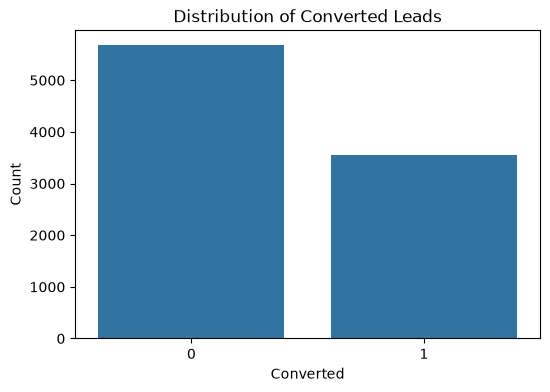

In [31]:
# Plotting distribution of Converted variable
plt.figure(figsize=(6,4))
sns.countplot(x='Converted', data=leads)
plt.title('Distribution of Converted Leads')
plt.xlabel('Converted')
plt.ylabel('Count')
plt.show()

### Observation

The dataset contains 9240 leads. Out of these, 3561 leads were converted and 5679 leads were not converted. The overall conversion rate is approximately 38.54%.

This shows that the current conversion rate is low, and the company needs a lead scoring model to identify high-potential leads.

## 2. Lead Origin Analysis

Lead Origin tells us the point from where the lead was generated. We analyze whether some lead origins have better conversion rates than others.

In [32]:
# Checking count of leads by Lead Origin
leads['Lead Origin'].value_counts()

Lead Origin
Landing Page Submission    4886
API                        3580
Lead Add Form               718
Lead Import                  55
Quick Add Form                1
Name: count, dtype: int64

In [33]:
# Conversion rate by Lead Origin
lead_origin_conversion = leads.groupby('Lead Origin')['Converted'].mean().sort_values(ascending=False) * 100
round(lead_origin_conversion, 2)

Lead Origin
Quick Add Form             100.00
Lead Add Form               92.48
Landing Page Submission     36.19
API                         31.15
Lead Import                 23.64
Name: Converted, dtype: float64

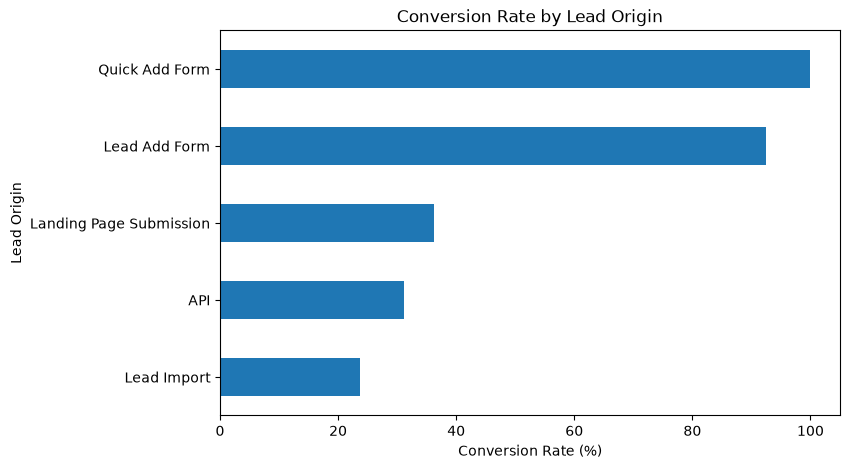

In [34]:
# Plotting conversion rate by Lead Origin
plt.figure(figsize=(8,5))
lead_origin_conversion.sort_values().plot(kind='barh')
plt.title('Conversion Rate by Lead Origin')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Lead Origin')
plt.show()

### Observation

Lead Add Form has a very high conversion rate of around 92%, while API and Landing Page Submission have much lower conversion rates. This indicates that leads coming through forms are generally more serious and more likely to convert.

Lead Origin is likely to be an important variable for the model.

## 3. Lead Source Analysis

Lead Source shows the channel through which the lead came, such as Google, Direct Traffic, Organic Search, Reference, etc. This helps identify high-quality marketing channels.

In [35]:
# Standardizing similar Lead Source values
leads['Lead Source'] = leads['Lead Source'].replace('google', 'Google')

In [36]:
# Checking lead counts by source
leads['Lead Source'].value_counts()

Lead Source
Google               2873
Direct Traffic       2543
Olark Chat           1755
Organic Search       1154
Reference             534
Welingak Website      142
Referral Sites        125
Facebook               55
bing                    6
Click2call              4
Social Media            2
Live Chat               2
Press_Release           2
Pay per Click Ads       1
blog                    1
WeLearn                 1
welearnblog_Home        1
youtubechannel          1
testone                 1
NC_EDM                  1
Name: count, dtype: int64

In [37]:
# Creating conversion rate table for Lead Source
lead_source_summary = leads.groupby('Lead Source').agg(
    Total_Leads=('Converted', 'count'),
    Converted_Leads=('Converted', 'sum'),
    Conversion_Rate=('Converted', 'mean')
).sort_values(by='Total_Leads', ascending=False)

lead_source_summary['Conversion_Rate'] = round(lead_source_summary['Conversion_Rate'] * 100, 2)

lead_source_summary

,Total_Leads,Converted_Leads,Conversion_Rate
Lead Source,,,
Google,2873,1147,39.92
Direct Traffic,2543,818,32.17
Olark Chat,1755,448,25.53
Organic Search,1154,436,37.78
Reference,534,490,91.76
Welingak Website,142,140,98.59
Referral Sites,125,31,24.80
Facebook,55,13,23.64
bing,6,1,16.67


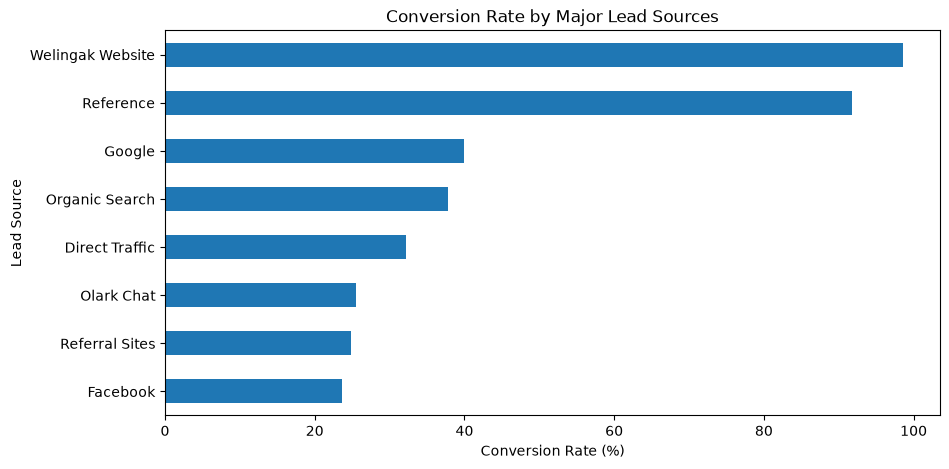

In [38]:
# Considering only sources with at least 50 leads for meaningful comparison
major_sources = lead_source_summary[lead_source_summary['Total_Leads'] >= 50]

plt.figure(figsize=(10,5))
major_sources.sort_values('Conversion_Rate')['Conversion_Rate'].plot(kind='barh')
plt.title('Conversion Rate by Major Lead Sources')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Lead Source')
plt.show()

### Observation

Welingak Website and Reference show very high conversion rates, above 90%. Google and Organic Search bring a high number of leads, but their conversion rates are moderate. Direct Traffic and Olark Chat have comparatively lower conversion rates.

This suggests that referral-based and website-specific leads are more valuable than generic traffic sources.

## 4. Total Time Spent on Website vs Conversion

Total time spent on the website may indicate the interest level of a lead. Leads spending more time on the website may have a higher chance of conversion.

In [39]:
# Checking average time spent by converted and non-converted leads
round(leads.groupby('Converted')['Total Time Spent on Website'].mean(), 2)

Converted
0    330.40
1    738.55
Name: Total Time Spent on Website, dtype: float64

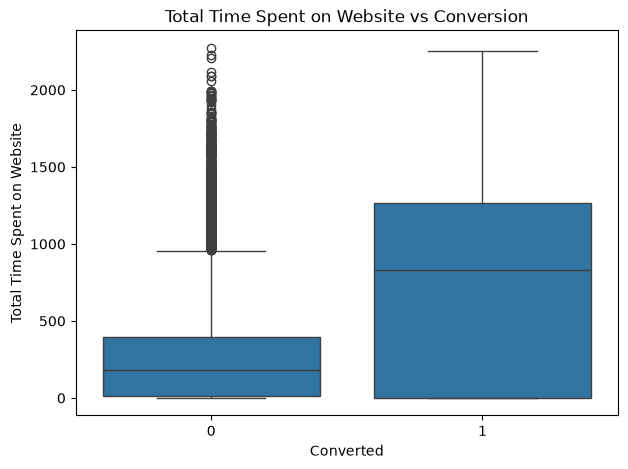

In [40]:
# Plotting Total Time Spent on Website against Converted
plt.figure(figsize=(7,5))
sns.boxplot(x='Converted', y='Total Time Spent on Website', data=leads)
plt.title('Total Time Spent on Website vs Conversion')
plt.xlabel('Converted')
plt.ylabel('Total Time Spent on Website')
plt.show()

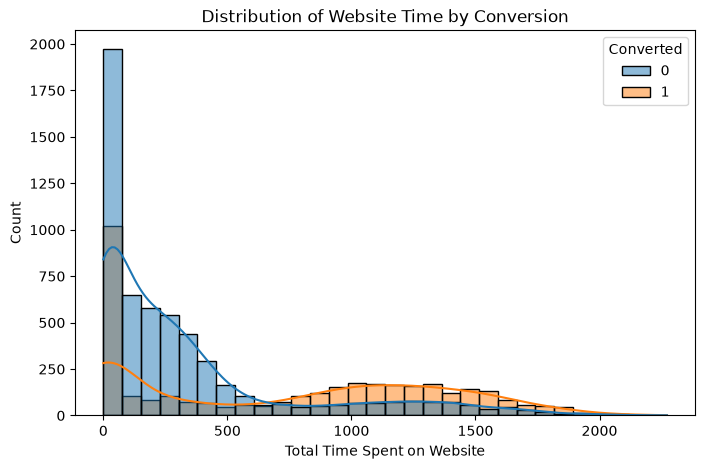

In [41]:
# Distribution of Total Time Spent on Website
plt.figure(figsize=(8,5))
sns.histplot(data=leads, x='Total Time Spent on Website', hue='Converted', bins=30, kde=True)
plt.title('Distribution of Website Time by Conversion')
plt.xlabel('Total Time Spent on Website')
plt.ylabel('Count')
plt.show()

### Observation

Converted leads spend much more time on the website compared to non-converted leads. The average time spent by converted leads is around 739 seconds, whereas non-converted leads spend around 330 seconds on average.

This is a strong indicator that website engagement is closely related to lead conversion.

## 5. Website Visit Behaviour

Total Visits and Page Views Per Visit show how actively leads interact with the website. These numerical variables are analyzed against conversion.

In [42]:
# Checking average visits and page views by conversion
round(leads.groupby('Converted')[['TotalVisits', 'Page Views Per Visit']].mean(), 2)

,TotalVisits,Page Views Per Visit
Converted,,
0,3.33,2.37
1,3.62,2.34


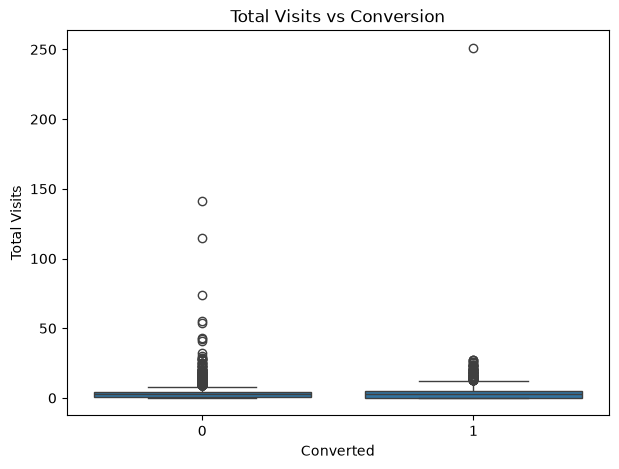

In [43]:
# Plotting TotalVisits against Converted
plt.figure(figsize=(7,5))
sns.boxplot(x='Converted', y='TotalVisits', data=leads)
plt.title('Total Visits vs Conversion')
plt.xlabel('Converted')
plt.ylabel('Total Visits')
plt.show()

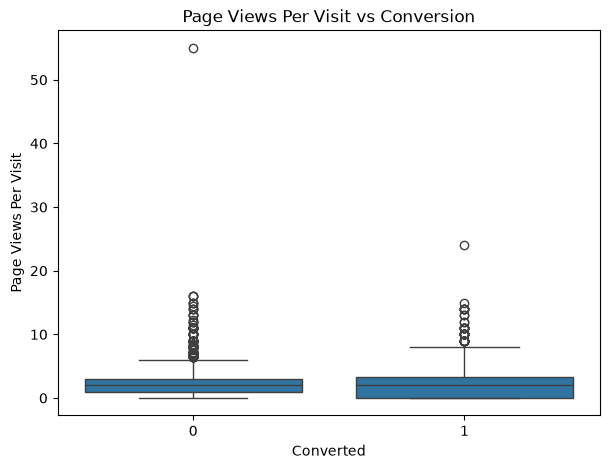

In [44]:
# Plotting Page Views Per Visit against Converted
plt.figure(figsize=(7,5))
sns.boxplot(x='Converted', y='Page Views Per Visit', data=leads)
plt.title('Page Views Per Visit vs Conversion')
plt.xlabel('Converted')
plt.ylabel('Page Views Per Visit')
plt.show()

### Observation

Converted and non-converted leads show only a small difference in Total Visits and Page Views Per Visit. However, both variables contain outliers, which should be kept in mind during model building.

Compared to these variables, Total Time Spent on Website appears to be a stronger predictor of conversion.

## 6. Current Occupation Analysis

The current occupation of a lead may influence their likelihood of enrolling in an online course. Therefore, conversion rates are analyzed across different occupation categories.

In [45]:
# Conversion rate by current occupation
occupation_summary = leads.groupby('What is your current occupation').agg(
    Total_Leads=('Converted', 'count'),
    Converted_Leads=('Converted', 'sum'),
    Conversion_Rate=('Converted', 'mean')
).sort_values(by='Conversion_Rate', ascending=False)

occupation_summary['Conversion_Rate'] = round(occupation_summary['Conversion_Rate'] * 100, 2)

occupation_summary

,Total_Leads,Converted_Leads,Conversion_Rate
What is your current occupation,,,
Housewife,10,10,100.00
Working Professional,706,647,91.64
Businessman,8,5,62.50
Other,16,10,62.50
Student,210,78,37.14
Unemployed,8290,2811,33.91


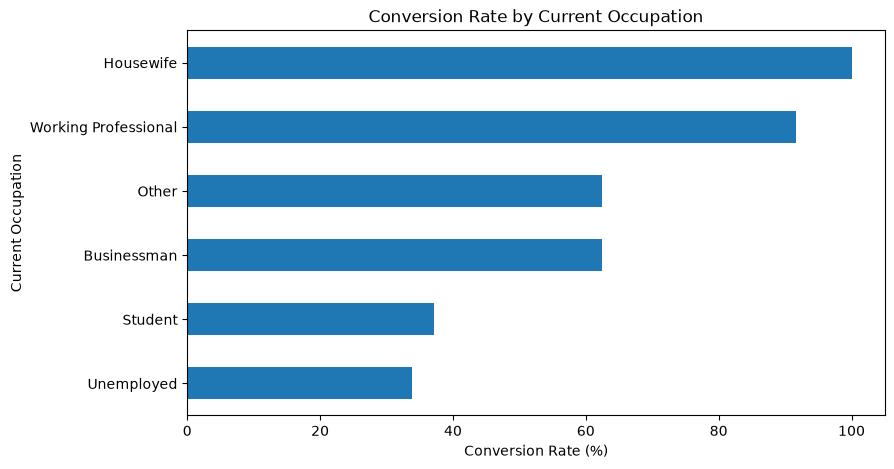

In [46]:
# Plotting conversion rate by occupation
plt.figure(figsize=(9,5))
occupation_summary.sort_values('Conversion_Rate')['Conversion_Rate'].plot(kind='barh')
plt.title('Conversion Rate by Current Occupation')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Current Occupation')
plt.show()

### Observation

Working Professionals show a very high conversion rate of around 92%. This makes business sense because the company sells online courses to industry professionals.

This variable is likely to be important for predicting conversion.

## 7. Last Activity Analysis

Last Activity represents the most recent interaction performed by the lead. This can be useful because recent engagement behaviour often indicates purchase intent.

In [47]:
# Conversion rate by Last Activity
last_activity_summary = leads.groupby('Last Activity').agg(
    Total_Leads=('Converted', 'count'),
    Converted_Leads=('Converted', 'sum'),
    Conversion_Rate=('Converted', 'mean')
).sort_values(by='Total_Leads', ascending=False)

last_activity_summary['Conversion_Rate'] = round(last_activity_summary['Conversion_Rate'] * 100, 2)

last_activity_summary

,Total_Leads,Converted_Leads,Conversion_Rate
Last Activity,,,
Email Opened,3540,1334,37.68
SMS Sent,2745,1727,62.91
Olark Chat Conversation,973,84,8.63
Page Visited on Website,640,151,23.59
Converted to Lead,428,54,12.62
Email Bounced,326,26,7.98
Email Link Clicked,267,73,27.34
Form Submitted on Website,116,28,24.14
Unreachable,93,31,33.33


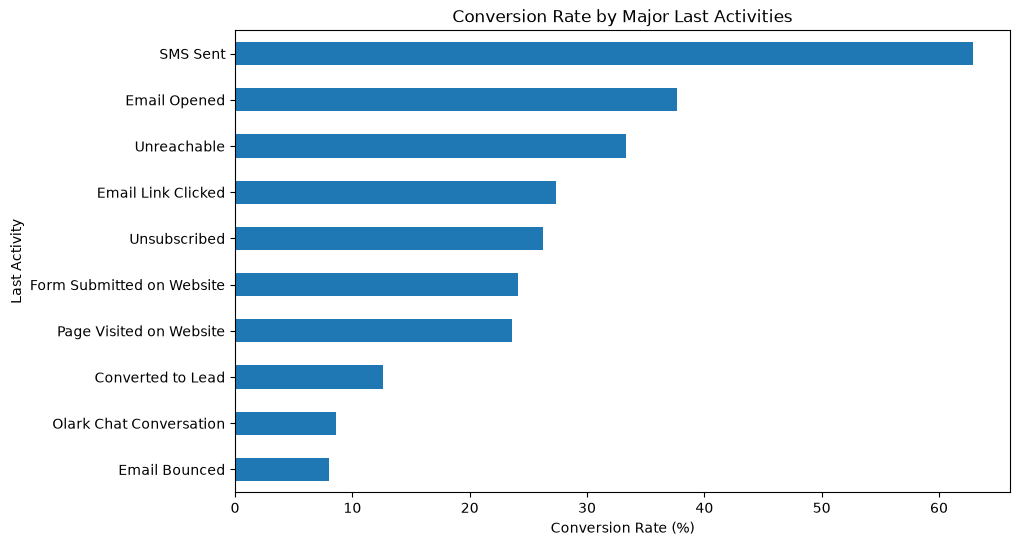

In [48]:
# Considering only activities with at least 50 leads
major_activities = last_activity_summary[last_activity_summary['Total_Leads'] >= 50]

plt.figure(figsize=(10,6))
major_activities.sort_values('Conversion_Rate')['Conversion_Rate'].plot(kind='barh')
plt.title('Conversion Rate by Major Last Activities')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Last Activity')
plt.show()

### Observation

Leads whose last activity was SMS Sent show a high conversion rate of around 63%. On the other hand, activities such as Email Bounced and Olark Chat Conversation show low conversion rates.

This indicates that recent communication activity is strongly linked with conversion probability.

## 8. Last Notable Activity Analysis

Last Notable Activity captures the most important recent interaction of the lead. This may help identify leads with stronger intent.

In [49]:
# Conversion rate by Last Notable Activity
last_notable_summary = leads.groupby('Last Notable Activity').agg(
    Total_Leads=('Converted', 'count'),
    Converted_Leads=('Converted', 'sum'),
    Conversion_Rate=('Converted', 'mean')
).sort_values(by='Total_Leads', ascending=False)

last_notable_summary['Conversion_Rate'] = round(last_notable_summary['Conversion_Rate'] * 100, 2)

last_notable_summary

,Total_Leads,Converted_Leads,Conversion_Rate
Last Notable Activity,,,
Modified,3407,783,22.98
Email Opened,2827,1044,36.93
SMS Sent,2172,1508,69.43
Page Visited on Website,318,93,29.25
Olark Chat Conversation,183,25,13.66
Email Link Clicked,173,45,26.01
Email Bounced,60,9,15.00
Unsubscribed,47,14,29.79
Unreachable,32,22,68.75


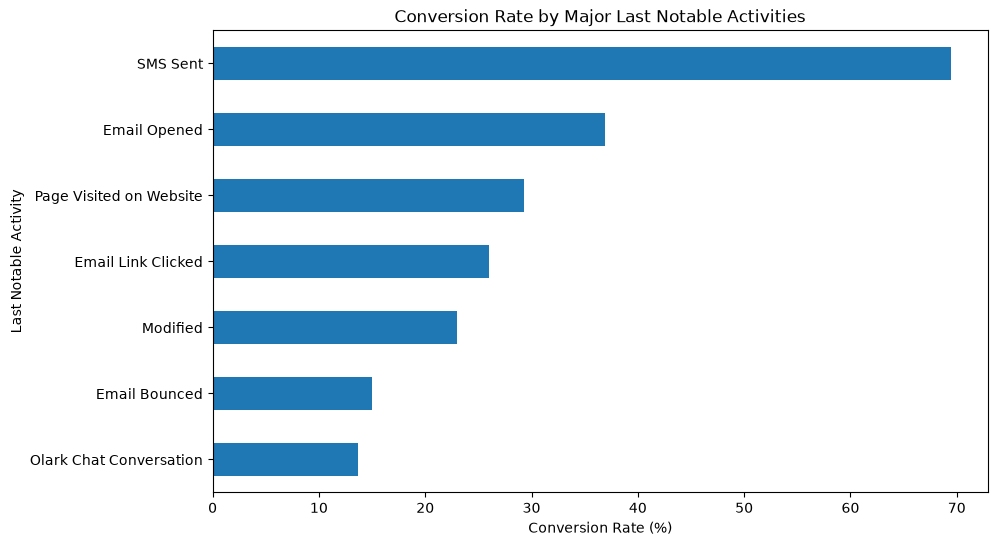

In [50]:
# Considering only notable activities with at least 50 leads
major_notable = last_notable_summary[last_notable_summary['Total_Leads'] >= 50]

plt.figure(figsize=(10,6))
major_notable.sort_values('Conversion_Rate')['Conversion_Rate'].plot(kind='barh')
plt.title('Conversion Rate by Major Last Notable Activities')
plt.xlabel('Conversion Rate (%)')
plt.ylabel('Last Notable Activity')
plt.show()

### Observation

Leads with Last Notable Activity as SMS Sent have a high conversion rate of around 69%. Modified and Olark Chat Conversation show comparatively lower conversion rates.

This again supports the insight that strong follow-up communication is linked with better conversion.

## 9. Do Not Email Analysis

The Do Not Email variable indicates whether a lead has opted out of email communication. This can affect the sales team's ability to nurture the lead.## 9. Do Not Email Analysis

The Do Not Email variable indicates whether a lead has opted out of email communication. This can affect the sales team's ability to nurture the lead.

In [51]:
# Conversion rate by Do Not Email
do_not_email_summary = leads.groupby('Do Not Email').agg(
    Total_Leads=('Converted', 'count'),
    Converted_Leads=('Converted', 'sum'),
    Conversion_Rate=('Converted', 'mean')
)

do_not_email_summary['Conversion_Rate'] = round(do_not_email_summary['Conversion_Rate'] * 100, 2)

do_not_email_summary

,Total_Leads,Converted_Leads,Conversion_Rate
Do Not Email,,,
No,8506,3443,40.48
Yes,734,118,16.08


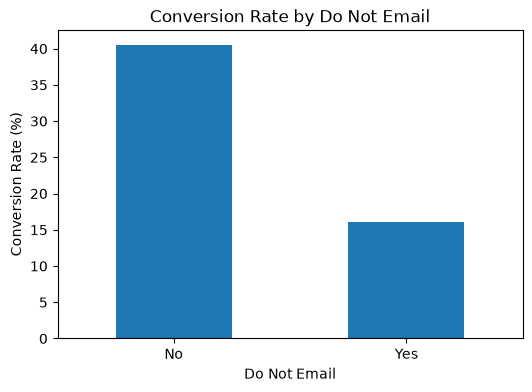

In [52]:
# Plotting conversion rate by Do Not Email
plt.figure(figsize=(6,4))
do_not_email_summary['Conversion_Rate'].plot(kind='bar')
plt.title('Conversion Rate by Do Not Email')
plt.xlabel('Do Not Email')
plt.ylabel('Conversion Rate (%)')
plt.xticks(rotation=0)
plt.show()

### Observation

Leads who did not opt out of emails show a higher conversion rate of around 40%, while leads marked as Do Not Email = Yes show a lower conversion rate of around 16%.

This suggests that leads open to email communication are easier to nurture and convert.

## 10. Correlation Analysis

A correlation heatmap is used to understand the relationship between numerical variables and the target variable.

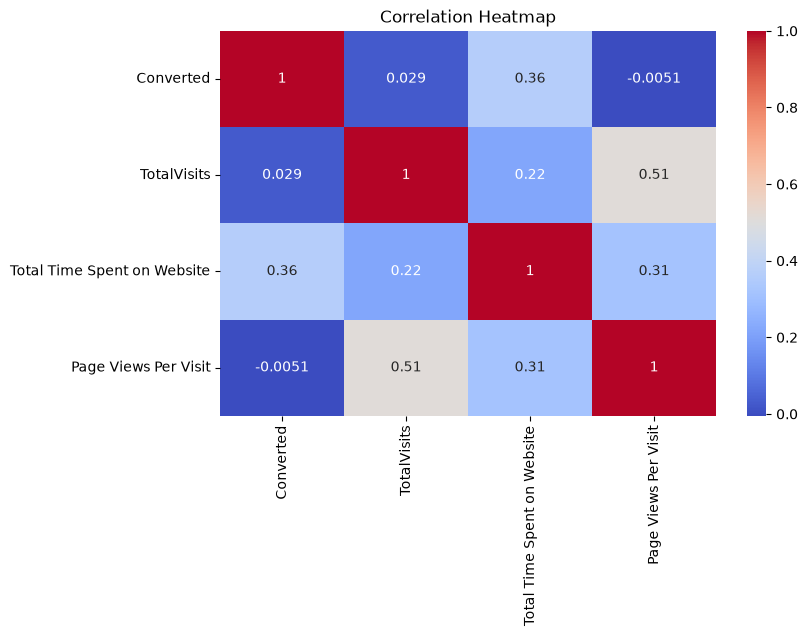

In [53]:
# Correlation heatmap for numerical variables
plt.figure(figsize=(8,5))
sns.heatmap(leads[['Converted', 'TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']].corr(),
            annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### Observation

Total Time Spent on Website has the strongest positive relationship with Converted among the numerical variables. TotalVisits and Page Views Per Visit have weaker relationships with conversion.

This supports the earlier observation that website engagement time is an important factor for lead conversion.

## EDA Summary

The following key insights were observed from the exploratory data analysis:

1. The overall conversion rate is approximately 38.54%, indicating scope for improvement.
2. Lead Add Form has a very high conversion rate, suggesting that form-based leads are highly valuable.
3. Welingak Website and Reference are high-converting lead sources.
4. Converted leads spend significantly more time on the website compared to non-converted leads.
5. Working Professionals show a much higher conversion rate than other occupation groups.
6. Last Activity and Last Notable Activity as SMS Sent are associated with higher conversion rates.
7. Leads who opted out of email communication have a lower conversion rate.

These insights will be useful during model building and business recommendation creation.

# Data Preparation for Model Building

In this section, the cleaned dataset is prepared for logistic regression modelling. Categorical variables are converted into dummy variables, the dataset is split into train and test sets, and numerical variables are scaled.

In [54]:
# Checking remaining columns after cleaning and EDA
leads.columns

Index(['Lead Origin', 'Lead Source', 'Do Not Email', 'Converted',
       'TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit',
       'Last Activity', 'Country', 'What is your current occupation',
       'What matters most to you in choosing a course',
       'Last Notable Activity'],
      dtype='object')

In [55]:
# Checking categorical columns
categorical_cols = leads.select_dtypes(include='object').columns
categorical_cols

Index(['Lead Origin', 'Lead Source', 'Do Not Email', 'Last Activity',
       'Country', 'What is your current occupation',
       'What matters most to you in choosing a course',
       'Last Notable Activity'],
      dtype='object')

In [56]:
# Checking numerical columns
numerical_cols = leads.select_dtypes(include=['int64', 'float64']).columns
numerical_cols

Index(['Converted', 'TotalVisits', 'Total Time Spent on Website',
       'Page Views Per Visit'],
      dtype='object')

In [57]:
# Checking value distribution of categorical columns
for col in categorical_cols:
    print(col)
    print(round(leads[col].value_counts(normalize=True) * 100, 2))
    print('--------------------------------')

Lead Origin
Lead Origin
Landing Page Submission    52.88
API                        38.74
Lead Add Form               7.77
Lead Import                 0.60
Quick Add Form              0.01
Name: proportion, dtype: float64
--------------------------------
Lead Source
Lead Source
Google               31.21
Direct Traffic       27.63
Olark Chat           19.07
Organic Search       12.54
Reference             5.80
Welingak Website      1.54
Referral Sites        1.36
Facebook              0.60
bing                  0.07
Click2call            0.04
Social Media          0.02
Live Chat             0.02
Press_Release         0.02
Pay per Click Ads     0.01
blog                  0.01
WeLearn               0.01
welearnblog_Home      0.01
youtubechannel        0.01
testone               0.01
NC_EDM                0.01
Name: proportion, dtype: float64
--------------------------------
Do Not Email
Do Not Email
No     92.06
Yes     7.94
Name: proportion, dtype: float64
------------------------------

Country
What matters most to you in choosing a course

In [58]:
# Checking current columns
leads.columns

Index(['Lead Origin', 'Lead Source', 'Do Not Email', 'Converted',
       'TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit',
       'Last Activity', 'Country', 'What is your current occupation',
       'What matters most to you in choosing a course',
       'Last Notable Activity'],
      dtype='object')

In [59]:
# Dropping highly skewed columns if they exist in the dataset

cols_to_drop_3 = ['Country', 'What matters most to you in choosing a course']

leads = leads.drop(columns=cols_to_drop_3, errors='ignore')

In [60]:
# Checking shape after dropping highly skewed columns
leads.shape

(9240, 10)

In [61]:
leads.columns

Index(['Lead Origin', 'Lead Source', 'Do Not Email', 'Converted',
       'TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit',
       'Last Activity', 'What is your current occupation',
       'Last Notable Activity'],
      dtype='object')

In [62]:
leads = leads.drop(columns=['Country', 'What matters most to you in choosing a course'], errors='ignore')
leads.shape

(9240, 10)

In [63]:
# Converting binary categorical variable into numeric format

leads['Do Not Email'] = leads['Do Not Email'].map({'Yes': 1, 'No': 0})

In [64]:
# Checking whether Do Not Email has been converted properly
leads['Do Not Email'].value_counts()

Do Not Email
0    8506
1     734
Name: count, dtype: int64

In [65]:
# Creating dummy variables for remaining categorical variables

dummy_cols = leads.select_dtypes(include='object').columns

dummies = pd.get_dummies(leads[dummy_cols], drop_first=True, dtype=int)

dummies.head()

,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Direct Traffic,Lead Source_Facebook,Lead Source_Google,Lead Source_Live Chat,Lead Source_NC_EDM,Lead Source_Olark Chat,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,0,0,0,0,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,1,0,0,0,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [66]:
# Dropping original categorical columns
leads = leads.drop(dummy_cols, axis=1)

# Concatenating dummy variables with the main dataset
leads = pd.concat([leads, dummies], axis=1)

# Checking the first few rows
leads.head()

,Do Not Email,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Direct Traffic,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
0,0,0,0.0,0,0.0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
1,0,0,5.0,674,2.5,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,1,2.0,1532,2.0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,0,0,1.0,305,1.0,1,0,0,0,1,...,0,0,1,0,0,0,0,0,0,0
4,0,1,2.0,1428,1.0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [67]:
# Checking shape after dummy variable creation
leads.shape

(9240, 64)

X = all input variables
y = target variable Converted

## Train-Test Split

The dataset is split into training and testing sets. The training data is used to build the model, while the testing data is used to evaluate its performance on unseen data.

In [68]:
# Separating target variable from independent variables

X = leads.drop('Converted', axis=1)
y = leads['Converted']

In [69]:
# Splitting the data into train and test sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, test_size=0.3, random_state=100
)

In [70]:
# Checking shapes of train and test data

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(6468, 63)
(2772, 63)
(6468,)
(2772,)


## Feature Scaling

Numerical variables are scaled using StandardScaler so that variables with larger ranges do not dominate the model.

In [71]:
# Scaling numerical variables

scaler = StandardScaler()

num_vars = ['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']

X_train[num_vars] = scaler.fit_transform(X_train[num_vars])

X_train.head()

,Do Not Email,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Direct Traffic,Lead Source_Facebook,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
1871,0,-0.656434,-0.885371,-1.085519,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6795,0,0.100767,0.005716,-0.470569,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3516,0,0.290067,-0.691418,0.070401,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8105,0,0.290067,1.365219,1.226321,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3934,0,-0.656434,-0.885371,-1.085519,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [72]:
# Checking summary after scaling
X_train[num_vars].describe()

,TotalVisits,Total Time Spent on Website,Page Views Per Visit
count,6.468000e+03,6.468000e+03,6.468000e+03
mean,3.295653e-17,-6.701161e-17,-1.428116e-17
std,1.000077e+00,1.000077e+00,1.000077e+00
min,-6.564336e-01,-8.853708e-01,-1.085519e+00
25%,-4.671335e-01,-8.634138e-01,-6.231508e-01
50%,-8.853323e-02,-4.352528e-01,-1.607829e-01
75%,2.900670e-01,8.098906e-01,3.015850e-01
max,4.685790e+01,3.271816e+00,2.434472e+01


# Logistic Regression Model Building

In this section, a logistic regression model is built to predict the probability of lead conversion. Feature selection will be performed using RFE, p-values, and VIF to obtain a stable and interpretable final model.

In [73]:
# Building logistic regression model using sklearn for RFE

logreg = LogisticRegression()

# Fitting the model on training data
logreg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

A logistic regression model has been fitted on the training data. This model will be used for Recursive Feature Elimination.

## Feature Selection Using RFE

Recursive Feature Elimination is used to select the most important variables from the dataset. Since dummy variable creation increases the number of columns, RFE helps reduce the feature set to the most useful predictors.

In [74]:
# Running RFE to select top 15 features

rfe = RFE(estimator=logreg, n_features_to_select=15)
rfe = rfe.fit(X_train, y_train)

In [75]:
# Creating a dataframe to view RFE ranking

rfe_results = pd.DataFrame({
    'Feature': X_train.columns,
    'Selected': rfe.support_,
    'Ranking': rfe.ranking_
})

rfe_results.sort_values(by='Ranking').head(20)

,Feature,Selected,Ranking
0,Do Not Email,True,1
55,Last Notable Activity_Modified,True,1
57,Last Notable Activity_Page Visited on Website,True,1
13,Lead Source_Olark Chat,True,1
28,Last Activity_Email Bounced,True,1
51,Last Notable Activity_Email Opened,True,1
56,Last Notable Activity_Olark Chat Conversation,True,1
35,Last Activity_Olark Chat Conversation,True,1
34,Last Activity_Had a Phone Conversation,True,1
49,Last Notable Activity_Email Link Clicked,True,1


In [76]:
# Storing columns selected by RFE

selected_cols = X_train.columns[rfe.support_]

selected_cols

Index(['Do Not Email', 'Total Time Spent on Website',
       'Lead Origin_Lead Add Form', 'Lead Source_Olark Chat',
       'Lead Source_Welingak Website', 'Last Activity_Email Bounced',
       'Last Activity_Had a Phone Conversation',
       'Last Activity_Olark Chat Conversation',
       'What is your current occupation_Housewife',
       'What is your current occupation_Working Professional',
       'Last Notable Activity_Email Link Clicked',
       'Last Notable Activity_Email Opened', 'Last Notable Activity_Modified',
       'Last Notable Activity_Olark Chat Conversation',
       'Last Notable Activity_Page Visited on Website'],
      dtype='object')

RFE selected the top 15 variables that are likely to be useful for predicting lead conversion. These variables will now be used to build a logistic regression model using statsmodels.

## Model 1: Logistic Regression Using RFE Selected Variables

The first model is built using the variables selected by RFE. Statsmodels is used because it provides p-values, which help identify statistically significant variables.

In [77]:
# Creating training dataset using RFE selected columns

X_train_rfe = X_train[selected_cols]

In [78]:
# Adding constant for statsmodels

X_train_sm = sm.add_constant(X_train_rfe)

In [79]:
# Building logistic regression model using statsmodels

logm1 = sm.GLM(y_train, X_train_sm, family=sm.families.Binomial())

res1 = logm1.fit()

# Displaying model summary
res1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6452
Model Family:                Binomial   Df Model:                           15
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2698.2
Date:                Thu, 29 Oct 2026   Deviance:                       5396.5
Time:                        04:53:21   Pearson chi2:                 7.71e+03
No. Iterations:                    21   Pseudo R-squ. (CS):             0.3904
Covariance Type:            nonrobust                                         
========================================================================================================================
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                                                    0.0765      0.068      1.125      0.261      -0.057       0.210
Do Not Email                                            -1.2490      0.195     -6.404      0.000      -1.631      -0.867
Total Time Spent on Website                              1.0985      0.039     27.968      0.000       1.022       1.176
Lead Origin_Lead Add Form                                3.7891      0.191     19.869      0.000       3.415       4.163
Lead Source_Olark Chat                                   1.1702      0.102     11.443      0.000       0.970       1.371
Lead Source_Welingak Website                             1.9756      0.744      2.655      0.008       0.517       3.434
Last Activity_Email Bounced                             -1.0826      0.347     -3.120      0.002      -1.763      -0.403
Last Activity_Had a Phone Conversation                   1.4515      0.683      2.125      0.034       0.113       2.790
Last Activity_Olark Chat Conversation                   -1.0861      0.192     -5.654      0.000      -1.463      -0.710
What is your current occupation_Housewife               22.9764   1.37e+04      0.002      0.999   -2.68e+04    2.69e+04
What is your current occupation_Working Professional     2.7556      0.187     14.751      0.000       2.390       3.122
Last Notable Activity_Email Link Clicked                -1.9036      0.272     -6.994      0.000      -2.437      -1.370
Last Notable Activity_Email Opened                      -1.3173      0.087    -15.202      0.000      -1.487      -1.147
Last Notable Activity_Modified                          -1.8299      0.096    -19.157      0.000      -2.017      -1.643
Last Notable Activity_Olark Chat Conversation           -1.5814      0.373     -4.245      0.000      -2.312      -0.851
Last Notable Activity_Page Visited on Website           -1.5822      0.191     -8.269      0.000      -1.957      -1.207
========================================================================================================================
"""

The first logistic regression model has been built using RFE selected variables. The p-values will be checked to remove statistically insignificant variables.

## Checking Multicollinearity Using VIF

Variance Inflation Factor is used to check multicollinearity among independent variables. A VIF value below 5 is generally considered acceptable.

In [80]:
# Function to calculate VIF for all features

def calculate_vif(X):
    vif = pd.DataFrame()
    vif['Features'] = X.columns
    vif['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    vif['VIF'] = round(vif['VIF'], 2)
    vif = vif.sort_values(by='VIF', ascending=False)
    return vif

In [81]:
# Checking VIF values for RFE selected variables

calculate_vif(X_train_rfe)

,Features,VIF
7,Last Activity_Olark Chat Conversation,1.92
0,Do Not Email,1.80
5,Last Activity_Email Bounced,1.79
3,Lead Source_Olark Chat,1.66
12,Last Notable Activity_Modified,1.55
2,Lead Origin_Lead Add Form,1.41
13,Last Notable Activity_Olark Chat Conversation,1.30
4,Lead Source_Welingak Website,1.24
1,Total Time Spent on Website,1.20
9,What is your current occupation_Working Profes...,1.14


VIF values are checked to identify multicollinearity. Variables with high VIF values may need to be removed, especially if they also have high p-values.

## Model 2: Removing Insignificant Variable

In Model 1, the VIF values were acceptable for all variables. However, the variable `What is your current occupation_Housewife` had a very high p-value, indicating that it is not statistically significant. Therefore, it is removed and the model is rebuilt.

In [82]:
# Dropping variable with high p-value

X_train_model2 = X_train_rfe.drop('What is your current occupation_Housewife', axis=1)

In [83]:
# Adding constant
X_train_sm2 = sm.add_constant(X_train_model2)

# Building logistic regression model
logm2 = sm.GLM(y_train, X_train_sm2, family=sm.families.Binomial())

res2 = logm2.fit()

# Displaying summary
res2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              Converted   No. Observations:                 6468
Model:                            GLM   Df Residuals:                     6453
Model Family:                Binomial   Df Model:                           14
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2705.6
Date:                Thu, 29 Oct 2026   Deviance:                       5411.2
Time:                        04:53:21   Pearson chi2:                 7.74e+03
No. Iterations:                     7   Pseudo R-squ. (CS):             0.3891
Covariance Type:            nonrobust                                         
========================================================================================================================
                                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------------
const                                                    0.0777      0.068      1.144      0.253      -0.055       0.211
Do Not Email                                            -1.2521      0.195     -6.420      0.000      -1.634      -0.870
Total Time Spent on Website                              1.0975      0.039     27.977      0.000       1.021       1.174
Lead Origin_Lead Add Form                                3.8056      0.190     19.995      0.000       3.433       4.179
Lead Source_Olark Chat                                   1.1637      0.102     11.394      0.000       0.964       1.364
Lead Source_Welingak Website                             1.9515      0.744      2.623      0.009       0.493       3.410
Last Activity_Email Bounced                             -1.0863      0.347     -3.129      0.002      -1.767      -0.406
Last Activity_Had a Phone Conversation                   1.4465      0.683      2.118      0.034       0.108       2.785
Last Activity_Olark Chat Conversation                   -1.0914      0.192     -5.684      0.000      -1.468      -0.715
What is your current occupation_Working Professional     2.7494      0.187     14.720      0.000       2.383       3.115
Last Notable Activity_Email Link Clicked                -1.8852      0.270     -6.991      0.000      -2.414      -1.357
Last Notable Activity_Email Opened                      -1.3111      0.087    -15.144      0.000      -1.481      -1.141
Last Notable Activity_Modified                          -1.8217      0.095    -19.101      0.000      -2.009      -1.635
Last Notable Activity_Olark Chat Conversation           -1.5728      0.372     -4.223      0.000      -2.303      -0.843
Last Notable Activity_Page Visited on Website           -1.5819      0.191     -8.269      0.000      -1.957      -1.207
========================================================================================================================
"""

In [84]:
# Checking p-values in descending order

p_values_model2 = pd.DataFrame({
    'Feature': res2.pvalues.index,
    'P_Value': res2.pvalues.values,
    'Coefficient': res2.params.values
})

p_values_model2.sort_values(by='P_Value', ascending=False)

,Feature,P_Value,Coefficient
0,const,2.526359e-01,0.077718
7,Last Activity_Had a Phone Conversation,3.414454e-02,1.446470
5,Lead Source_Welingak Website,8.712007e-03,1.951485
6,Last Activity_Email Bounced,1.752502e-03,-1.086269
13,Last Notable Activity_Olark Chat Conversation,2.412525e-05,-1.572821
8,Last Activity_Olark Chat Conversation,1.313166e-08,-1.091434
1,Do Not Email,1.363225e-10,-1.252111
10,Last Notable Activity_Email Link Clicked,2.726665e-12,-1.885151
14,Last Notable Activity_Page Visited on Website,1.348724e-16,-1.581947
4,Lead Source_Olark Chat,4.504686e-30,1.163689


In [85]:
# Checking VIF values for Model 2

calculate_vif(X_train_model2)

,Features,VIF
7,Last Activity_Olark Chat Conversation,1.92
0,Do Not Email,1.80
5,Last Activity_Email Bounced,1.79
3,Lead Source_Olark Chat,1.66
11,Last Notable Activity_Modified,1.55
2,Lead Origin_Lead Add Form,1.41
12,Last Notable Activity_Olark Chat Conversation,1.30
4,Lead Source_Welingak Website,1.24
1,Total Time Spent on Website,1.20
8,What is your current occupation_Working Profes...,1.14


### Observation

After removing the insignificant variable, Model 2 was built. The p-values and VIF values were checked again to ensure that the model contains statistically significant variables and does not suffer from multicollinearity.

Since all VIF values are below 5, multicollinearity is not a concern.

## Final Model Selection

Model 2 is selected as the final model because all predictor variables have acceptable p-values and all VIF values are below 5. This indicates that the model is statistically significant and does not suffer from multicollinearity.

# Model Evaluation

In this section, the final logistic regression model is evaluated using predicted probabilities, confusion matrix, accuracy, sensitivity, specificity, ROC curve, and AUC score.

In [86]:
# Predicting conversion probabilities on the training data

y_train_pred = res2.predict(sm.add_constant(X_train_model2))

# Displaying first few predicted probabilities
y_train_pred[:10]

1871    0.260891
6795    0.226689
3516    0.303965
8105    0.828635
3934    0.174808
4844    0.992397
3297    0.115644
8071    0.997454
987     0.253688
7423    0.904190
dtype: float64

In [87]:
# Creating a dataframe with actual conversion values and predicted probabilities

y_train_pred_final = pd.DataFrame({
    'Converted': y_train.values,
    'Converted_Prob': y_train_pred
})

# Resetting index
y_train_pred_final.reset_index(drop=True, inplace=True)

# Displaying first few rows
y_train_pred_final.head()

,Converted,Converted_Prob
0,0,0.260891
1,0,0.226689
2,0,0.303965
3,0,0.828635
4,0,0.174808


## Choosing Initial Cutoff

Initially, a cutoff of 0.5 is used. Leads with predicted probability greater than 0.5 are classified as converted, and the remaining leads are classified as not converted.

In [88]:
# Creating predicted class using cutoff of 0.5

y_train_pred_final['Predicted'] = y_train_pred_final['Converted_Prob'].map(
    lambda x: 1 if x > 0.5 else 0
)

y_train_pred_final.head()

,Converted,Converted_Prob,Predicted
0,0,0.260891,0
1,0,0.226689,0
2,0,0.303965,0
3,0,0.828635,1
4,0,0.174808,0


In [89]:
# Creating confusion matrix

confusion = confusion_matrix(y_train_pred_final['Converted'], y_train_pred_final['Predicted'])
confusion

array([[3545,  457],
       [ 752, 1714]])

In [90]:
# Assigning confusion matrix values

TP = confusion[1,1]  # True Positives
TN = confusion[0,0]  # True Negatives
FP = confusion[0,1]  # False Positives
FN = confusion[1,0]  # False Negatives

# Calculating metrics

accuracy = round((TP + TN) / float(TP + TN + FP + FN), 3)
sensitivity = round(TP / float(TP + FN), 3)
specificity = round(TN / float(TN + FP), 3)

print("Accuracy:", accuracy)
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Accuracy: 0.813
Sensitivity: 0.695
Specificity: 0.886


### Observation

At the initial cutoff of 0.5, accuracy, sensitivity, and specificity are calculated. However, the cutoff needs to be optimized because the business objective is to identify hot leads effectively.

## ROC Curve and AUC

The ROC curve shows the trade-off between sensitivity and specificity at different cutoff values. AUC measures the overall ability of the model to distinguish between converted and non-converted leads.

In [91]:
# Function to plot ROC curve

def draw_roc(actual, probs):
    fpr, tpr, thresholds = roc_curve(actual, probs)
    auc_score = roc_auc_score(actual, probs)
    
    plt.figure(figsize=(7,5))
    plt.plot(fpr, tpr, label='ROC Curve')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve')
    plt.legend(loc='lower right')
    plt.show()
    
    return auc_score

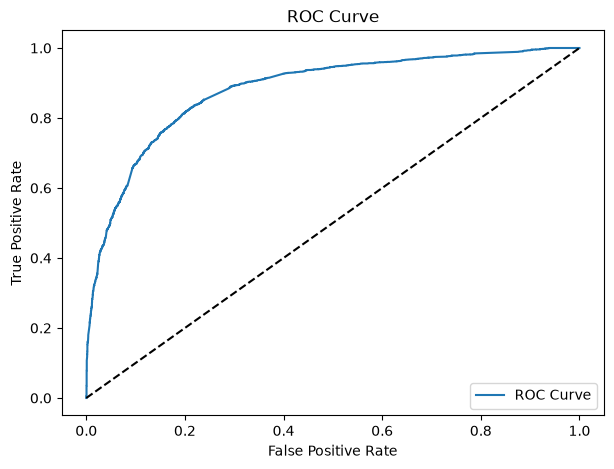

AUC Score: 0.881


In [92]:
# Plotting ROC curve and calculating AUC score

auc_score = draw_roc(y_train_pred_final['Converted'], y_train_pred_final['Converted_Prob'])

print("AUC Score:", round(auc_score, 3))

A higher AUC score indicates that the model is good at separating converted leads from non-converted leads.

## Finding Optimal Cutoff

Different probability cutoffs are tested to find a balance between accuracy, sensitivity, and specificity. The optimal cutoff should help identify hot leads while keeping false predictions under control.

In [93]:
# Creating prediction columns for different cutoff values

numbers = [float(x)/10 for x in range(10)]

for i in numbers:
    y_train_pred_final[i] = y_train_pred_final['Converted_Prob'].map(
        lambda x: 1 if x > i else 0
    )

y_train_pred_final.head()

,Converted,Converted_Prob,Predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0,0,0.260891,0,1,1,1,0,0,0,0,0,0,0
1,0,0.226689,0,1,1,1,0,0,0,0,0,0,0
2,0,0.303965,0,1,1,1,1,0,0,0,0,0,0
3,0,0.828635,1,1,1,1,1,1,1,1,1,1,0
4,0,0.174808,0,1,1,0,0,0,0,0,0,0,0


In [94]:
# Creating a dataframe to store accuracy, sensitivity, and specificity for different cutoffs

cutoff_df = pd.DataFrame(columns=['Probability', 'Accuracy', 'Sensitivity', 'Specificity'])

for i in numbers:
    cm = confusion_matrix(y_train_pred_final['Converted'], y_train_pred_final[i])
    
    TP = cm[1,1]
    TN = cm[0,0]
    FP = cm[0,1]
    FN = cm[1,0]
    
    accuracy = (TP + TN) / float(TP + TN + FP + FN)
    sensitivity = TP / float(TP + FN)
    specificity = TN / float(TN + FP)
    
    cutoff_df.loc[i] = [i, accuracy, sensitivity, specificity]

cutoff_df

,Probability,Accuracy,Sensitivity,Specificity
0.0,0.0,0.381262,1.000000,0.000000
0.1,0.1,0.584725,0.966748,0.349325
0.2,0.2,0.757421,0.903893,0.667166
0.3,0.3,0.800557,0.838200,0.777361
0.4,0.4,0.812307,0.765612,0.841079
0.5,0.5,0.813080,0.695053,0.885807
0.6,0.6,0.796073,0.588402,0.924038
0.7,0.7,0.782777,0.512571,0.949275
0.8,0.8,0.758967,0.412003,0.972764
0.9,0.9,0.714904,0.270884,0.988506


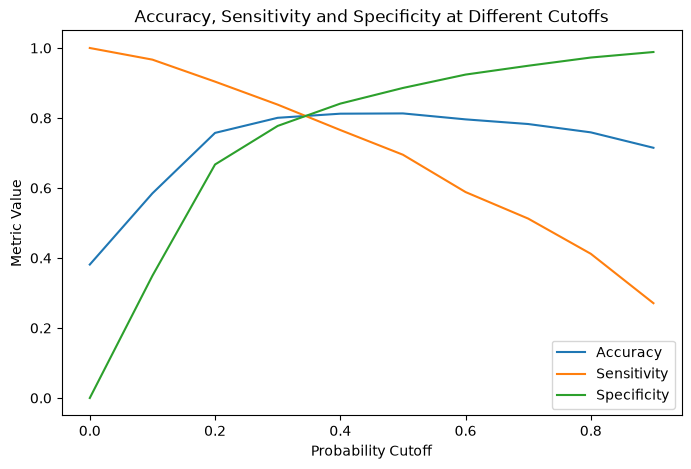

In [95]:
# Plotting accuracy, sensitivity, and specificity for different cutoffs

cutoff_df.plot.line(x='Probability', y=['Accuracy', 'Sensitivity', 'Specificity'], figsize=(8,5))
plt.title('Accuracy, Sensitivity and Specificity at Different Cutoffs')
plt.xlabel('Probability Cutoff')
plt.ylabel('Metric Value')
plt.show()

In [96]:
# Selecting cutoff where sensitivity and specificity are closest

cutoff_df['Difference'] = abs(cutoff_df['Sensitivity'] - cutoff_df['Specificity'])

optimal_cutoff = cutoff_df.sort_values('Difference').iloc[0]['Probability']

print("Optimal Cutoff:", optimal_cutoff)

Optimal Cutoff: 0.3


### Observation

The optimal cutoff is selected based on the balance between sensitivity and specificity. This cutoff will be used to classify leads as hot or cold.

### Optimal Cutoff Selection

Based on the accuracy, sensitivity, and specificity table, the cutoff of 0.3 provides a good balance between sensitivity and specificity. Since the business objective is to identify potential hot leads, sensitivity is important because we do not want to miss too many convertible leads.

Therefore, 0.3 is selected as the optimal cutoff.

In [97]:
# Setting optimal cutoff based on sensitivity-specificity trade-off

optimal_cutoff = 0.3

print("Optimal Cutoff:", optimal_cutoff)

Optimal Cutoff: 0.3


## Final Evaluation on Training Data

The final predicted class is created using the selected cutoff of 0.3. The training data is evaluated using confusion matrix, accuracy, sensitivity, and specificity.

In [98]:
# Creating final prediction using optimal cutoff

y_train_pred_final['Final_Predicted'] = y_train_pred_final['Converted_Prob'].map(
    lambda x: 1 if x > optimal_cutoff else 0
)

y_train_pred_final.head()

,Converted,Converted_Prob,Predicted,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,Final_Predicted
0,0,0.260891,0,1,1,1,0,0,0,0,0,0,0,0
1,0,0.226689,0,1,1,1,0,0,0,0,0,0,0,0
2,0,0.303965,0,1,1,1,1,0,0,0,0,0,0,1
3,0,0.828635,1,1,1,1,1,1,1,1,1,1,0,1
4,0,0.174808,0,1,1,0,0,0,0,0,0,0,0,0


In [99]:
# Final confusion matrix on training data

confusion_final = confusion_matrix(
    y_train_pred_final['Converted'], 
    y_train_pred_final['Final_Predicted']
)

confusion_final

array([[3111,  891],
       [ 399, 2067]])

In [100]:
# Calculating final metrics on training data

TP = confusion_final[1,1]
TN = confusion_final[0,0]
FP = confusion_final[0,1]
FN = confusion_final[1,0]

train_accuracy = round((TP + TN) / float(TP + TN + FP + FN), 3)
train_sensitivity = round(TP / float(TP + FN), 3)
train_specificity = round(TN / float(TN + FP), 3)

print("Training Accuracy:", train_accuracy)
print("Training Sensitivity:", train_sensitivity)
print("Training Specificity:", train_specificity)

Training Accuracy: 0.801
Training Sensitivity: 0.838
Training Specificity: 0.777


### Training Data Observation

At the cutoff of 0.3, the model provides a good balance between accuracy, sensitivity, and specificity. The sensitivity is relatively high, which means the model is able to identify a large proportion of actual converted leads.

# Model Evaluation on Test Data

The final model is evaluated on the test dataset to check how well it performs on unseen data. The same transformations used on the training data are applied to the test data.

In [101]:
# Scaling numerical variables in test data using the same scaler fitted on training data

X_test[num_vars] = scaler.transform(X_test[num_vars])

X_test.head()

,Do Not Email,TotalVisits,Total Time Spent on Website,Page Views Per Visit,Lead Origin_Landing Page Submission,Lead Origin_Lead Add Form,Lead Origin_Lead Import,Lead Origin_Quick Add Form,Lead Source_Direct Traffic,Lead Source_Facebook,...,Last Notable Activity_Form Submitted on Website,Last Notable Activity_Had a Phone Conversation,Last Notable Activity_Modified,Last Notable Activity_Olark Chat Conversation,Last Notable Activity_Page Visited on Website,Last Notable Activity_Resubscribed to emails,Last Notable Activity_SMS Sent,Last Notable Activity_Unreachable,Last Notable Activity_Unsubscribed,Last Notable Activity_View in browser link Clicked
4269,0,0.857967,0.964504,2.613424,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
2376,0,-0.656434,-0.885371,-1.085519,0,1,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
7766,0,0.290067,-0.777416,1.226321,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
9199,0,-0.656434,-0.885371,-1.085519,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4359,0,-0.656434,-0.885371,-1.085519,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [102]:
# Selecting the same variables used in the final model

final_cols = X_train_model2.columns

X_test_model2 = X_test[final_cols]

In [103]:
# Adding constant to test data

X_test_sm = sm.add_constant(X_test_model2)

# Predicting probabilities on test data

y_test_pred = res2.predict(X_test_sm)

y_test_pred[:10]

4269    0.756985
2376    0.948419
7766    0.878033
9199    0.066399
4359    0.832095
9186    0.582975
1631    0.457389
8963    0.158842
8007    0.116619
5324    0.360626
dtype: float64

In [104]:
# Creating dataframe with actual and predicted probabilities for test data

y_test_pred_final = pd.DataFrame({
    'Converted': y_test.values,
    'Converted_Prob': y_test_pred
})

y_test_pred_final.reset_index(drop=True, inplace=True)

y_test_pred_final.head()

,Converted,Converted_Prob
0,1,0.756985
1,1,0.948419
2,1,0.878033
3,0,0.066399
4,1,0.832095


In [105]:
# Creating final prediction using optimal cutoff of 0.3

y_test_pred_final['Final_Predicted'] = y_test_pred_final['Converted_Prob'].map(
    lambda x: 1 if x > optimal_cutoff else 0
)

y_test_pred_final.head()

,Converted,Converted_Prob,Final_Predicted
0,1,0.756985,1
1,1,0.948419,1
2,1,0.878033,1
3,0,0.066399,0
4,1,0.832095,1


In [106]:
# Confusion matrix on test data

confusion_test = confusion_matrix(
    y_test_pred_final['Converted'], 
    y_test_pred_final['Final_Predicted']
)

confusion_test

array([[1307,  370],
       [ 178,  917]])

In [107]:
# Calculating metrics on test data

TP = confusion_test[1,1]
TN = confusion_test[0,0]
FP = confusion_test[0,1]
FN = confusion_test[1,0]

test_accuracy = round((TP + TN) / float(TP + TN + FP + FN), 3)
test_sensitivity = round(TP / float(TP + FN), 3)
test_specificity = round(TN / float(TN + FP), 3)

print("Test Accuracy:", test_accuracy)
print("Test Sensitivity:", test_sensitivity)
print("Test Specificity:", test_specificity)

Test Accuracy: 0.802
Test Sensitivity: 0.837
Test Specificity: 0.779


In [108]:
# Calculating AUC score on test data

test_auc = roc_auc_score(
    y_test_pred_final['Converted'], 
    y_test_pred_final['Converted_Prob']
)

print("Test AUC Score:", round(test_auc, 3))

Test AUC Score: 0.883


### Test Data Observation

The final model was evaluated on test data using the selected cutoff of 0.3. The test accuracy, sensitivity, specificity, and AUC score were checked to ensure that the model performs well on unseen data.

If the test metrics are close to the training metrics, the model can be considered stable and suitable for lead scoring.

# Lead Score Creation

The predicted probability of conversion is converted into a lead score between 0 and 100. A higher lead score indicates a higher probability of conversion, while a lower score indicates a colder lead.

In [109]:
# Creating lead score for test data

y_test_pred_final['Lead_Score'] = round(y_test_pred_final['Converted_Prob'] * 100, 0)

y_test_pred_final.head()

,Converted,Converted_Prob,Final_Predicted,Lead_Score
0,1,0.756985,1,76.0
1,1,0.948419,1,95.0
2,1,0.878033,1,88.0
3,0,0.066399,0,7.0
4,1,0.832095,1,83.0


In [110]:
# Checking lead score distribution

y_test_pred_final['Lead_Score'].describe()

count    2772.000000
mean       37.805195
std        31.462676
min         1.000000
25%        11.000000
50%        26.000000
75%        61.000000
max       100.000000
Name: Lead_Score, dtype: float64

In [111]:
# Categorizing leads based on lead score

def lead_category(score):
    if score >= 80:
        return 'Hot Lead'
    elif score >= 50:
        return 'Warm Lead'
    else:
        return 'Cold Lead'

y_test_pred_final['Lead_Category'] = y_test_pred_final['Lead_Score'].apply(lead_category)

y_test_pred_final.head()

,Converted,Converted_Prob,Final_Predicted,Lead_Score,Lead_Category
0,1,0.756985,1,76.0,Warm Lead
1,1,0.948419,1,95.0,Hot Lead
2,1,0.878033,1,88.0,Hot Lead
3,0,0.066399,0,7.0,Cold Lead
4,1,0.832095,1,83.0,Hot Lead


In [112]:
# Checking count of leads in each category

y_test_pred_final['Lead_Category'].value_counts()

Lead_Category
Cold Lead    1846
Hot Lead      464
Warm Lead     462
Name: count, dtype: int64

### Lead Score Observation

The predicted conversion probabilities were converted into lead scores ranging from 0 to 100. Leads with higher scores should be prioritized by the sales team, as they have a higher probability of conversion.

Hot leads can be contacted first, followed by warm leads. Cold leads may be deprioritized to improve sales efficiency.

# Important Variables from Final Model

The final model coefficients are analyzed to identify the variables that contribute most towards lead conversion.

In [113]:
# Extracting final model coefficients

final_coefficients = pd.DataFrame({
    'Feature': res2.params.index,
    'Coefficient': res2.params.values
})

# Removing constant
final_coefficients = final_coefficients[final_coefficients['Feature'] != 'const']

# Sorting by absolute coefficient value
final_coefficients['Abs_Coefficient'] = abs(final_coefficients['Coefficient'])

final_coefficients.sort_values(by='Abs_Coefficient', ascending=False)

,Feature,Coefficient,Abs_Coefficient
3,Lead Origin_Lead Add Form,3.805584,3.805584
9,What is your current occupation_Working Profes...,2.749395,2.749395
5,Lead Source_Welingak Website,1.951485,1.951485
10,Last Notable Activity_Email Link Clicked,-1.885151,1.885151
12,Last Notable Activity_Modified,-1.821678,1.821678
14,Last Notable Activity_Page Visited on Website,-1.581947,1.581947
13,Last Notable Activity_Olark Chat Conversation,-1.572821,1.572821
7,Last Activity_Had a Phone Conversation,1.446470,1.446470
11,Last Notable Activity_Email Opened,-1.311095,1.311095
1,Do Not Email,-1.252111,1.252111


In [114]:
# Top positive variables increasing conversion probability

positive_coefficients = final_coefficients[final_coefficients['Coefficient'] > 0]

positive_coefficients.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient,Abs_Coefficient
3,Lead Origin_Lead Add Form,3.805584,3.805584
9,What is your current occupation_Working Profes...,2.749395,2.749395
5,Lead Source_Welingak Website,1.951485,1.951485
7,Last Activity_Had a Phone Conversation,1.446470,1.446470
4,Lead Source_Olark Chat,1.163689,1.163689
2,Total Time Spent on Website,1.097456,1.097456


In [115]:
# Top negative variables decreasing conversion probability

negative_coefficients = final_coefficients[final_coefficients['Coefficient'] < 0]

negative_coefficients.sort_values(by='Coefficient', ascending=True)

,Feature,Coefficient,Abs_Coefficient
10,Last Notable Activity_Email Link Clicked,-1.885151,1.885151
12,Last Notable Activity_Modified,-1.821678,1.821678
14,Last Notable Activity_Page Visited on Website,-1.581947,1.581947
13,Last Notable Activity_Olark Chat Conversation,-1.572821,1.572821
11,Last Notable Activity_Email Opened,-1.311095,1.311095
1,Do Not Email,-1.252111,1.252111
8,Last Activity_Olark Chat Conversation,-1.091434,1.091434
6,Last Activity_Email Bounced,-1.086269,1.086269


### Important Variable Observation

The most important variables are identified using the coefficients from the final logistic regression model. Positive coefficients increase the probability of conversion, while negative coefficients decrease the probability of conversion.

# Business Recommendations and Conclusion

Based on the final logistic regression model and EDA, the following recommendations can be made:

1. Leads with high lead scores should be prioritized by the sales team.
2. Leads coming through Lead Add Form, Reference, and Welingak Website should be given higher attention as they show strong conversion potential.
3. Leads spending more time on the website should be treated as more engaged and should be contacted quickly.
4. Working professionals should be prioritized because they show a high probability of conversion.
5. Leads with negative activities such as Email Bounced or Do Not Email should be deprioritized.
6. During aggressive sales periods, the company can use a lower cutoff to capture more potential leads.
7. During periods where targets are already met, the company can use a higher cutoff to call only the strongest leads.

The final model can help X Education improve sales efficiency by allowing the sales team to focus on hot leads instead of contacting every lead equally.